# EuroSAT Land-Cover Classification — A Comparative Deep Learning Study with Transfer Learning

# Notebook 05 — Transfer Learning Fundamentals

## 1. Objective

Notebooks 01–04 built and tuned a CNN trained **from scratch**. This notebook introduces **Transfer Learning**: using a CNN already pretrained on ImageNet — **MobileNetV2** — as a fixed feature extractor for EuroSAT, training only a small new classification head on top of it.

The goal is to understand the fundamental transfer-learning workflow, not to compare architectures (that's Notebook 06) or to fine-tune the backbone (that's Notebook 07). This notebook only performs **feature extraction**: the pretrained backbone stays frozen throughout.

## 2. Transfer Learning Concept

- **Training from scratch** (Notebooks 03–04): a CNN starts with randomly initialized weights and has to learn every feature — edges, textures, shapes, class-specific patterns — from the 21,600 EuroSAT training images alone.
- **Transfer Learning / Feature Extraction** (this notebook): a CNN already trained on a much larger dataset (ImageNet, ~1.4M images, 1000 classes) is reused. Its convolutional layers already know how to detect general visual features (edges, textures, color patterns, simple shapes). We keep those pretrained weights **frozen** and only train a small new classification head that maps those existing features to EuroSAT's 10 classes.
- **Fine-Tuning** (Notebook 07): after feature extraction, some of the pretrained backbone's upper layers are later unfrozen and trained with a small learning rate, letting the model adapt its features specifically to EuroSAT. **Fine-tuning is not performed in this notebook.**

## 3. Why MobileNetV2?

MobileNetV2 is a CNN pretrained on ImageNet that's relatively small and fast, which makes it a practical starting point for learning the transfer-learning workflow before comparing six pretrained architectures in Notebook 06 (VGG16, InceptionV3, ResNet50, DenseNet121, MobileNetV2, EfficientNetB0).

## 4. Imports


In [16]:
from pathlib import Path
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split

## 5. Configuration

`DATASET_ROOT` below is a relative path: place the EuroSAT RGB dataset in `data/EuroSAT_RGB/` next to this notebook, or **change it to the location of the dataset on your machine before running this notebook.**


In [ ]:
DATASET_ROOT = Path("data/EuroSAT_RGB")

CLASS_NAMES = [
    "AnnualCrop", "Forest", "HerbaceousVegetation",
    "Highway", "Industrial", "Pasture",
    "PermanentCrop", "Residential", "River",
    "SeaLake",
]

CLASS_TO_ID = {class_name: idx for idx, class_name in enumerate(CLASS_NAMES)}
EXPECTED_EXTENSIONS = {".jpg", ".jpeg"}

SEED = 42
IMAGE_SIZE = (128, 128)   # MobileNetV2 input size for this notebook (see Section 9)
NUM_CLASSES = 10
BATCH_SIZE = 32
EPOCHS = 15

## 6. Reproducibility

Same `SEED = 42` used throughout the project, set consistently across Python, NumPy, and TensorFlow. Fully deterministic execution is not enforced in this environment, so repeating a run may give somewhat different numbers; the results below are the results of the recorded run.


In [18]:
def set_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


set_seeds(SEED)

## 7. Dataset and Stratified Split

This notebook is standalone and does not depend on runtime state from earlier notebooks: the manifest and the same two-stage stratified 80/10/10 split (`SEED = 42`) are recreated here identically to Notebook 02. `test_df` is recreated only so the split's arithmetic is consistent and visible — **no `test_ds` is built from it, and it is not used anywhere below.** The test set stays reserved for Notebook 08.

In [19]:
records = []
for class_name in CLASS_NAMES:
    class_dir = DATASET_ROOT / class_name
    for path in class_dir.iterdir():
        if path.is_file() and path.suffix.lower() in EXPECTED_EXTENSIONS:
            records.append((str(path), class_name, CLASS_TO_ID[class_name]))

manifest_df = pd.DataFrame(records, columns=["filepath", "class_name", "label"])

train_df, temp_df = train_test_split(
    manifest_df, test_size=0.20, stratify=manifest_df["label"], random_state=SEED,
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED,
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Train:      {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"(Test set:  {len(test_df)} — not loaded into a tf.data.Dataset in this notebook)")

Train:      21600
Validation: 2700
(Test set:  2700 — not loaded into a tf.data.Dataset in this notebook)


## 8. TensorFlow Input Pipeline

This section builds the `tf.data` input pipeline from the manifest and split recreated above (the `load_image` function below). The image resizing and the model-specific preprocessing it applies are explained in Section 9.


## 9. MobileNetV2 Preprocessing

The original EuroSAT images are 64×64, but MobileNetV2's convolutional backbone downsamples spatially several times internally — at 64×64 the feature map would shrink to a size too small for the network's later layers, so **images are resized to 128×128×3 inside the pipeline** (the original files on disk are never touched or resized).

MobileNetV2 also expects a specific input scaling: pixel values roughly in **`[-1, 1]`**, produced by `tf.keras.applications.mobilenet_v2.preprocess_input` (which internally computes `x / 127.5 - 1`). This is different from the `[0, 1]` scaling used in Notebooks 02–04 for the from-scratch CNN. If the wrong scaling is used — or if `[0, 1]` scaling is applied *before* `preprocess_input`, effectively scaling twice — the pretrained backbone receives inputs far outside the range it was trained on, and its pretrained features become far less useful (in the worst case, close to meaningless).

To keep this unambiguous, `load_image` below decodes and resizes the image, casts it to `float32` **without dividing by 255**, and then applies `preprocess_input` exactly once — that single call is the only scaling step in this pipeline.

In [ ]:
def load_image(filepath, label):
    ##Read a JPEG file, decode it, resize to IMAGE_SIZE, and apply MobileNetV2's expected
    #preprocessing (scales to roughly [-1, 1]). Pixel values are intentionally NOT divided by
    #255 first — preprocess_input is the only scaling step, applied once#
    image = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label


def make_dataset(df, shuffle, seed=SEED, batch_size=BATCH_SIZE):
    filepaths = df["filepath"].values
    labels = df["label"].values

    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=seed, reshuffle_each_iteration=True)

    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df, shuffle=False)

print("train_ds:", train_ds)
print("val_ds:  ", val_ds)

train_ds: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
val_ds:   <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


## 10. Load Pretrained MobileNetV2

`include_top=False` removes MobileNetV2's original ImageNet classification head (which predicts 1000 ImageNet classes) — we only want its convolutional feature-extracting backbone, since EuroSAT has 10 classes, not 1000.

In [21]:
IMG_SHAPE = IMAGE_SIZE + (3,)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights="imagenet",
)

print(f"Backbone input shape:  {base_model.input_shape}")
print(f"Backbone output shape: {base_model.output_shape}")
print(f"Backbone layers: {len(base_model.layers)}")

Backbone input shape:  (None, 128, 128, 3)
Backbone output shape: (None, 4, 4, 1280)
Backbone layers: 154


## 11. Inspect Backbone

The **backbone** is this pretrained convolutional network — its weights encode general visual feature representations learned from ImageNet (edges, textures, shapes, and more complex patterns built from those). It outputs a stack of feature maps, not class predictions (since `include_top=False`).

In [22]:
base_model.summary()

Model: "mobilenetv2_1.00_128"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 64, 64,    │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 64, 64,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 64, 64,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 64, 64,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 64, 64,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 64, 64,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 65, 65,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 32, 32,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 32, 32,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 2,223,872 (8.48 MB)

 Non-trainable params: 34,112 (133.25 KB)

## 12. Freeze Backbone

Setting `base_model.trainable = False` freezes every weight in the backbone: during training, gradients still flow *through* it (so the new head can learn), but none of its own weights are updated. This is what makes this experiment **feature extraction** rather than fine-tuning — verified explicitly below via the model's actual parameter counts, not just asserted.

In [23]:
base_model.trainable = False

## 13. Build Classification Head

The **classification head** is the new part we're adding: `GlobalAveragePooling2D` collapses the backbone's spatial feature maps into one vector per image (the same operation used in Notebook 04's GAP experiment), a small `Dropout(0.2)` helps reduce overfitting in this newly-initialized head, and `Dense(10, softmax)` maps that vector to the 10 EuroSAT classes. This head is intentionally simple — no BatchNormalization, no extra Dense layers — to isolate the effect of the pretrained features themselves.

`base_model(inputs, training=False)` is used even though `base_model.trainable` is already `False`: this additionally forces the backbone's BatchNormalization layers to run in inference mode (using their fixed pretrained statistics) rather than potentially updating their running mean/variance from EuroSAT batches — the standard pattern for frozen pretrained backbones.

In [24]:
inputs = tf.keras.Input(shape=IMG_SHAPE)
x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="mobilenetv2_feature_extractor")

## 14. Verify Trainable Parameters

The actual parameter counts below confirm what's frozen and what isn't — not just the `trainable = False` line, but the real numbers.

In [25]:
model.summary()

total_params = model.count_params()
trainable_params = sum(int(tf.size(w)) for w in model.trainable_weights)
non_trainable_params = sum(int(tf.size(w)) for w in model.non_trainable_weights)

print(f"\nTotal parameters:         {total_params:,}")
print(f"Trainable parameters:     {trainable_params:,}  (the new classification head only)")
print(f"Non-trainable parameters: {non_trainable_params:,}  (the frozen MobileNetV2 backbone)")

Model: "mobilenetv2_feature_extractor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Total parameters:         2,270,794
Trainable parameters:     12,810  (the new classification head only)
Non-trainable parameters: 2,257,984  (the frozen MobileNetV2 backbone)


## 15. Compile Model

In [26]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

## 16. Train Feature-Extraction Model

Only the classification head has trainable weights (12,810 parameters), but every training image still passes through the full frozen backbone at 128×128 in each epoch, so a small trainable-parameter count does not by itself mean fast epochs (the recorded epoch times are shown below). Same `EarlyStopping` configuration used throughout the project: monitor `val_loss`, patience 5, `restore_best_weights=True`, at most 15 epochs.


In [27]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

start_time = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    shuffle=False,  # train_ds is already shuffled by the pipeline (Section 8)
    verbose=2,
)
training_time_s = round(time.time() - start_time, 1)

print(f"\nTraining time: {training_time_s}s")

Epoch 1/15
675/675 - 96s - 142ms/step - accuracy: 0.8631 - loss: 0.4081 - val_accuracy: 0.9259 - val_loss: 0.2219
Epoch 2/15
675/675 - 95s - 141ms/step - accuracy: 0.9202 - loss: 0.2339 - val_accuracy: 0.9356 - val_loss: 0.2020
Epoch 3/15
675/675 - 93s - 138ms/step - accuracy: 0.9297 - loss: 0.2035 - val_accuracy: 0.9344 - val_loss: 0.1860
Epoch 4/15
675/675 - 98s - 145ms/step - accuracy: 0.9347 - loss: 0.1855 - val_accuracy: 0.9322 - val_loss: 0.1937
Epoch 5/15
675/675 - 118s - 175ms/step - accuracy: 0.9365 - loss: 0.1777 - val_accuracy: 0.9344 - val_loss: 0.1870
Epoch 6/15
675/675 - 120s - 177ms/step - accuracy: 0.9421 - loss: 0.1648 - val_accuracy: 0.9370 - val_loss: 0.1814
Epoch 7/15
675/675 - 118s - 175ms/step - accuracy: 0.9433 - loss: 0.1614 - val_accuracy: 0.9307 - val_loss: 0.1915
Epoch 8/15
675/675 - 120s - 178ms/step - accuracy: 0.9445 - loss: 0.1554 - val_accuracy: 0.9363 - val_loss: 0.1890
Epoch 9/15
675/675 - 101s - 150ms/step - accuracy: 0.9476 - loss: 0.1497 - val_accur

## 17. Training Curves

In [28]:
history_df = pd.DataFrame(history.history)
history_df.index = history_df.index + 1
history_df.index.name = "epoch"

history_df

,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.863102,0.408108,0.925926,0.221943
2,0.920231,0.233858,0.935556,0.201980
3,0.929722,0.203545,0.934444,0.186025
4,0.934676,0.185456,0.932222,0.193740
5,0.936481,0.177702,0.934444,0.186994
6,0.942083,0.164804,0.937037,0.181368
7,0.943333,0.161387,0.930741,0.191484
8,0.944537,0.155360,0.936296,0.188990
9,0.947593,0.149688,0.933704,0.193930


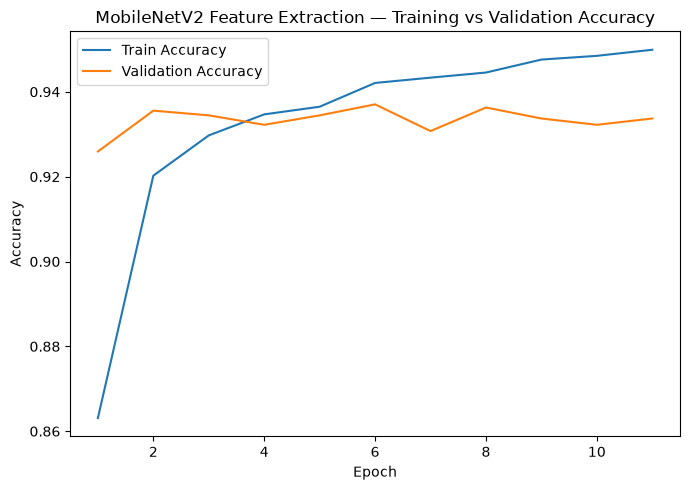

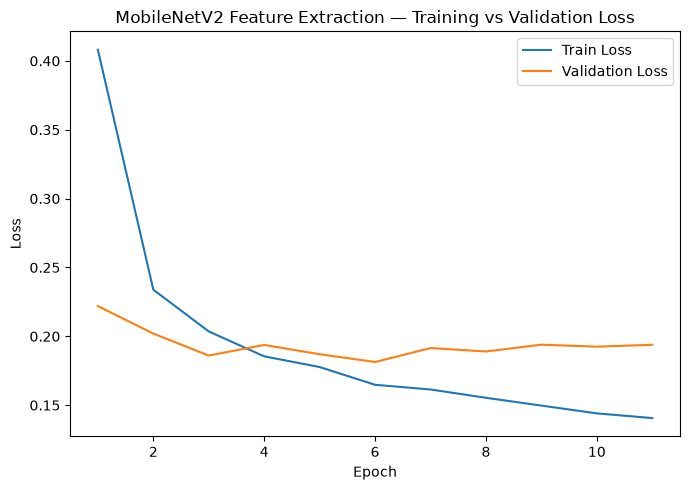

In [29]:
plt.figure(figsize=(7, 5))
plt.plot(history_df.index, history_df["accuracy"], label="Train Accuracy")
plt.plot(history_df.index, history_df["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Feature Extraction — Training vs Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(history_df.index, history_df["loss"], label="Train Loss")
plt.plot(history_df.index, history_df["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV2 Feature Extraction — Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** Validation accuracy was already 92.59% after the first epoch and stayed between 93.07% and 93.70% from Epoch 2 onward. Validation loss reached its minimum of 0.1814 at Epoch 6 and then stayed around 0.19 (0.1915, 0.1890, 0.1939, 0.1925, 0.1939), so `EarlyStopping` stopped the run at Epoch 11 (best-loss epoch 6 + patience 5) and restored the Epoch 6 weights. Training accuracy rose slowly and steadily (86.31% → 94.99%) while training loss fell (0.4081 → 0.1406), so the training/validation accuracy gap at Epoch 11 was 1.62 points (94.99% vs 93.37%); this is much smaller than the baseline's 13-point gap at the end of Notebook 03, although training metrics here are measured with Dropout active, so the comparison is only indicative. Compared with the Notebook 03 curves, validation performance plateaued much earlier (Epoch 2, versus Epoch 10 for the baseline) and was smoother: the largest epoch-to-epoch drop in validation accuracy was 0.63 points (Epoch 6 → 7), whereas the baseline's validation accuracy fell by 2.41 points between Epochs 6 and 7. The curves show mild overfitting at most; the plateau in validation metrics is consistent with a frozen backbone and a small head having limited room to improve, but this notebook does not test that explanation.


## 18. Validation Results

As established in Notebook 04's corrected reporting: the best validation **accuracy** epoch and the best validation **loss** epoch are not always the same, since `EarlyStopping` restores the best-*loss* weights specifically. Both are reported separately.

In [30]:
best_val_acc_epoch = int(history_df["val_accuracy"].idxmax())
best_val_acc = float(history_df["val_accuracy"].max())

best_val_loss_epoch = int(history_df["val_loss"].idxmin())
best_val_loss = float(history_df["val_loss"].min())

results_summary_df = pd.DataFrame(
    [
        ["Best Validation Accuracy", f"{best_val_acc:.2%}"],
        ["Best Validation Accuracy Epoch", best_val_acc_epoch],
        ["Best Validation Loss", f"{best_val_loss:.4f}"],
        ["Best Validation Loss Epoch", best_val_loss_epoch],
        ["Total Parameters", f"{total_params:,}"],
        ["Trainable Parameters", f"{trainable_params:,}"],
        ["Non-Trainable Parameters", f"{non_trainable_params:,}"],
        ["Training Time (s)", training_time_s],
    ],
    columns=["Metric", "Result"],
)

results_summary_df

,Metric,Result
0,Best Validation Accuracy,93.70%
1,Best Validation Accuracy Epoch,6
2,Best Validation Loss,0.1814
3,Best Validation Loss Epoch,6
4,Total Parameters,"2,270,794"
5,Trainable Parameters,"12,810"
6,Non-Trainable Parameters,"2,257,984"
7,Training Time (s),1140.4


## 19. Compare With Baseline CNN

The Notebook 03 from-scratch baseline is used as a fixed reference (not retrained here):

| | Baseline CNN (Notebook 03) | MobileNetV2 Feature Extraction |
|---|---:|---:|
| Best Validation Accuracy | 88.00% | 93.70% |
| Best Validation Loss | 0.3607 | 0.1814 |
| Best Epoch | 10 | 6 |
| Total Parameters | 684,490 | 2,270,794 |
| Trainable Parameters | 684,490 (all of them) | 12,810 (head only) |

**In this experiment** — using wording scoped to this one run, not a universal claim —:
- **Accuracy and loss:** the frozen ImageNet features gave higher validation accuracy than the from-scratch baseline (93.70% vs 88.00%, +5.70 points, about 154 of the 2,700 validation images) and a lower validation loss (0.1814 vs 0.3607).
- **Trainable parameters:** only 12,810 weights were trained (the new head), about 1.9% of the baseline's 684,490 trainable parameters. The total model is larger (2,270,794 parameters) because the 2,257,984 frozen backbone parameters are included in it.
- **Training behavior:** validation performance plateaued from about Epoch 2 and the curves were smoother, with a small training/validation gap (Section 17). Training was not faster per epoch: the recorded run took 1,140.4 seconds for 11 epochs (about 90–120 seconds per epoch at 128×128), whereas the baseline's epochs in Notebook 03 took about 22–29 seconds each at 64×64, because the frozen backbone is still evaluated on every image.
- **Overall:** in this particular experiment, transfer learning with a frozen MobileNetV2 was clearly better than the from-scratch baseline on both validation accuracy and validation loss. This is one run of one architecture on validation data.

This is deliberately framed as one experiment's result, not a general claim about transfer learning.


## 20. ImageNet / EuroSAT Domain Limitation

MobileNetV2 was pretrained on ImageNet — everyday photos of objects, animals, and scenes taken from a ground-level, close-up perspective. EuroSAT is satellite imagery: top-down views of land-cover types like crops, forests, and urban areas, at a very different scale and viewpoint from anything in ImageNet.

This is exactly what makes the experiment scientifically interesting rather than a foregone conclusion: it tests whether general-purpose visual features (edges, textures, color patterns) learned from a completely different visual domain still transfer usefully to satellite land-cover classification. There's no guarantee they will — the result in Section 18 is what actually answers that, for this specific setup.

## 21. Key Observations

1. **Performance of the frozen features:** frozen MobileNetV2 features reached 93.70% validation accuracy and 0.1814 validation loss (both best at Epoch 6) in this run.
2. **Parameter efficiency:** only the head was trained — 12,810 trainable parameters, compared with the baseline's 684,490 — while the 2,257,984 backbone parameters stayed frozen.
3. **Curve behavior:** validation accuracy was 92.59% after Epoch 1 and then plateaued between 93.07% and 93.70%; validation loss bottomed out at Epoch 6 and stayed near 0.19. `EarlyStopping` stopped training at Epoch 11. The final training/validation accuracy gap was small (94.99% vs 93.37%).
4. **Comparison with the baseline:** validation accuracy was 5.70 points higher (93.70% vs 88.00%) and validation loss was about half (0.1814 vs 0.3607), with the best epoch coming earlier (6 vs 10).
5. **Compute:** training took 1,140.4 seconds for 11 epochs — a small trainable-parameter count did not translate into shorter epochs than the baseline's, since the frozen backbone still processes every image at 128×128.
6. **Domain gap:** despite ImageNet and EuroSAT being very different image domains (Section 20), ImageNet features were useful for EuroSAT in this setup. This notebook does not explain why.
7. **Heading into Notebook 06:** this is one architecture and one run, so it should not be read as representative of transfer learning in general. Notebook 06 repeats the same frozen setup for six architectures.
8. The test set was not used.


## 22. Limitations

- Only one pretrained architecture (MobileNetV2) and one frozen-backbone configuration were tried here — no comparison across architectures (Notebook 06) or learning rates/head designs (out of scope, to avoid hyperparameter tuning).
- The backbone is entirely frozen: this measures how useful *off-the-shelf* ImageNet features are for EuroSAT, not the ceiling of what MobileNetV2 could achieve on this task — fine-tuning, which updates part of the backbone, is the subject of Notebook 07.
- Results come from a single training run at a single input resolution (128×128); no claim is made about sensitivity to those choices.
- As with every notebook before Notebook 08, this result is validation-only and has not been checked against the held-out test set.

## 23. Conclusion

This notebook implemented the fundamental transfer-learning workflow: loading MobileNetV2 with ImageNet weights, removing its original classifier (`include_top=False`), freezing the entire backbone, and training only a small new classification head (`GlobalAveragePooling2D` → `Dropout(0.2)` → `Dense(10, softmax)`) for EuroSAT's 10 classes — this is **feature extraction**, not fine-tuning: the backbone's pretrained weights were never updated.

In this particular run, the frozen MobileNetV2 features performed well: 93.70% validation accuracy and 0.1814 validation loss, compared with the Notebook 03 from-scratch CNN's 88.00% and 0.3607, while training only 12,810 head parameters. Training was not faster per epoch than the baseline, and the result comes from a single run on validation data.

This result motivates Notebook 06, which will compare six pretrained architectures (VGG16, InceptionV3, ResNet50, DenseNet121, MobileNetV2, EfficientNetB0) under the same frozen-feature-extraction setup, so this single result isn't over-interpreted as representative of transfer learning in general. Fine-tuning is intentionally postponed to Notebook 07, once a well-understood feature-extraction baseline — this notebook — is in place. No model here is being declared a final or best model.